# CardioRisk: exploratory data analysis

**BITS Pilani AIMLCZG523 MLOps, Assignment 1.** This notebook studies the data before any model is
trained. Its job is to justify the decisions baked into the training pipeline
(`src/cardiorisk/features.py`, `src/cardiorisk/train.py`), so every number quoted in the text is
computed in a code cell above it.

**Question.** Given the 13 routinely collected clinical attributes of a patient referred for
angiography, estimate the probability of angiographic heart disease (`target = 1` when
`num > 0`).

**Data source.** [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease)
(dataset id 45), the "processed" 14-attribute files from four hospitals: Cleveland Clinic,
the Hungarian Institute of Cardiology (Budapest), University Hospitals Zurich and Basel
(Switzerland), and the VA Medical Center Long Beach. Most published work uses Cleveland only;
this project pools all four sites (920 records instead of 303) and keeps the site label for
analysis and evaluation.

**Reproducing the data.** `make data` (equivalently `python -m cardiorisk.data`) downloads the
UCI archive, verifies each extracted file against the SHA-256 digests pinned in
`cardiorisk/data.py`, and writes `data/raw/` and `data/processed/heart_disease_clean.csv`. When
`data/raw/` already matches the digests no network access happens, so a checksum failure means
the upstream data changed, not that the analysis did. Re-run this notebook with `make notebook`.

In [1]:
%matplotlib inline
import pandas as pd
from sklearn.metrics import roc_auc_score

from cardiorisk import config, eda
from cardiorisk.data import RAW_SHA256, clean, load_processed, load_raw
from cardiorisk.features import INPUT_FEATURES, NUMERIC, add_clinical_features

pd.set_option("display.precision", 3)

## Data dictionary

The 14 attributes of the processed files, as documented in `data/raw/heart-disease.names`
(numbers in brackets are the attribute positions in the original 76-column database). `site` is
added by the loader and `target` by the cleaning step.

| Column | Meaning | Unit / codes | Pipeline role |
| --- | --- | --- | --- |
| `age` | Age | years | numeric |
| `sex` | Sex | 1 = male, 0 = female | binary |
| `cp` | Chest pain type | 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic | categorical |
| `trestbps` | Resting blood pressure on admission | mm Hg | numeric |
| `chol` | Serum cholesterol | mg/dl | numeric |
| `fbs` | Fasting blood sugar > 120 mg/dl | 1 = true, 0 = false | binary |
| `restecg` | Resting ECG | 0 normal, 1 ST-T wave abnormality, 2 probable/definite left ventricular hypertrophy | categorical |
| `thalach` | Maximum heart rate achieved on the exercise test | beats per minute | numeric |
| `exang` | Exercise-induced angina | 1 = yes, 0 = no | binary |
| `oldpeak` | ST depression induced by exercise relative to rest | mm (negative = ST elevation) | numeric |
| `slope` | Slope of the peak exercise ST segment | 1 upsloping, 2 flat, 3 downsloping | categorical |
| `ca` | Major vessels coloured by fluoroscopy | count 0-3 | categorical |
| `thal` | Thallium stress test | 3 normal, 6 fixed defect, 7 reversible defect | categorical |
| `num` | Angiographic diagnosis (predicted attribute) | 0 = < 50% diameter narrowing; 1-4 = > 50% narrowing | source of `target` |
| `site` | Collecting hospital (added by `load_raw`) | cleveland, hungarian, switzerland, va | EDA and evaluation only, never a model input |
| `target` | Heart disease present (added by `clean`) | 1 if `num > 0`, else 0 | label |

The model also derives `hr_achieved_frac = thalach / (220 - age)` inside the pipeline (section 7).

## 1. Raw data and what cleaning changes

`load_raw` stacks the four files (no header; `?` marks a missing value) and tags each row with
its site. The pinned digests guarantee these are the exact bytes every other result was
computed from.

In [2]:
raw = load_raw()
print(f"{len(raw)} raw rows, {len(RAW_SHA256)} files verified by SHA-256")
raw["site"].value_counts().rename("rows").to_frame().T

920 raw rows, 5 files verified by SHA-256


site,cleveland,hungarian,va,switzerland
rows,303,294,200,123


In [3]:
markers = raw[config.RAW_COLUMNS].isna().sum()
print(f"'?' markers in total: {markers.sum()}")
markers[markers > 0].rename("'?' markers").to_frame().T

'?' markers in total: 1759


,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
'?' markers,59,30,90,2,55,55,62,309,611,486


Beyond the `?` markers, two sites wrote `0` for a test that was not done. A cholesterol or
resting blood pressure of zero is impossible in a living patient, so `clean` treats those zeros
as missing. It also drops exact duplicate records, which could otherwise land on both sides of
the train/test split and inflate the hold-out score.

In [4]:
zeros = pd.DataFrame(
    {col: raw[col].eq(0).groupby(raw["site"]).sum() for col in ("trestbps", "chol")}
)
zeros.T.assign(total=zeros.sum()).rename_axis("zeros -> missing")

site,cleveland,hungarian,switzerland,va,total
zeros -> missing,,,,,
trestbps,0,0,0,1,1
chol,0,0,123,49,172


In [5]:
dupes = raw[raw.duplicated(keep=False)]
dupes[["site", "age", "sex", "cp", "trestbps", "chol", "thalach", "num"]]

,site,age,sex,cp,trestbps,chol,thalach,num
404,hungarian,49.0,0.0,2.0,110.0,NaN,160.0,0
405,hungarian,49.0,0.0,2.0,110.0,NaN,160.0,0
859,va,58.0,1.0,3.0,150.0,219.0,118.0,2
907,va,58.0,1.0,3.0,150.0,219.0,118.0,2


In [6]:
df = clean(raw)
assert df.equals(load_processed()), "data/processed is stale: run make data"
print(
    f"cleaned: {df.shape[0]} rows x {df.shape[1]} columns "
    f"({len(raw) - len(df)} duplicates dropped); matches data/processed"
)
print(f"negative oldpeak (ST elevation, kept): {(df['oldpeak'] < 0).sum()} rows")

cleaned: 918 rows x 16 columns (2 duplicates dropped); matches data/processed
negative oldpeak (ST elevation, kept): 12 rows


**What cleaning did.** 920 raw rows became 918: one duplicated Hungarian record and one
duplicated VA record were removed. 172 cholesterol zeros (all 123 Swiss rows and 49 VA rows) and
one VA blood-pressure zero became missing values on top of the 1,759 `?` markers. Nothing else
is altered: the 12 negative `oldpeak` values are ST elevation, a real finding, and extremes such
as `chol = 603` are clinically plausible, so no outlier clipping is applied. The table above is
asserted equal to `data/processed/heart_disease_clean.csv`, the file training reads.

## 2. Class balance, overall and per site

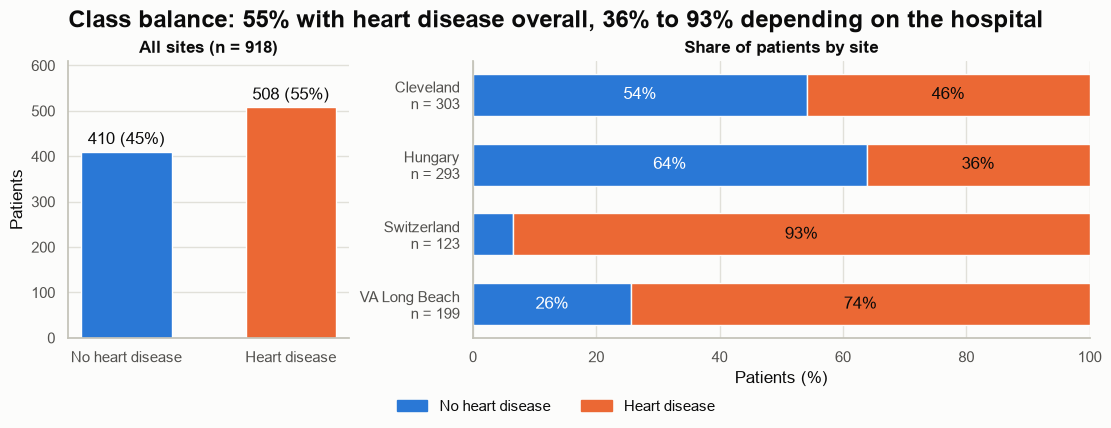

In [7]:
eda.plot_class_balance(df)

In [8]:
by_site = df.groupby("site")[config.TARGET].agg(patients="size", disease_rate="mean")
grades = (
    df.astype({"num": int}).groupby("site")["num"].value_counts().unstack(fill_value=0).astype(int)
)
by_site.join(grades.add_prefix("num=")).rename(index=eda.SITE_NAMES)

,patients,disease_rate,num=0,num=1,num=2,num=3,num=4
site,,,,,,,
Cleveland,303,0.459,164,55,36,35,13
Hungary,293,0.362,187,106,0,0,0
Switzerland,123,0.935,8,48,32,30,5
VA Long Beach,199,0.744,51,56,40,42,10


- Pooled, the classes are nearly balanced: 55% of the 918 patients have heart disease, so
  accuracy is not meaningless, but a majority-class model already scores 0.55.
- The pooled figure hides a large site effect: prevalence ranges from 36% in Hungary to 93% in
  Switzerland (115 of 123 patients). Switzerland has only 8 negatives.
- Hungary graded `num` only as 0/1 while the other sites used 0-4, so severity is not
  comparable across sites. The binary presence/absence target is the only label all four sites
  share, which is why the project predicts `num > 0`.

## 3. Missing values by site

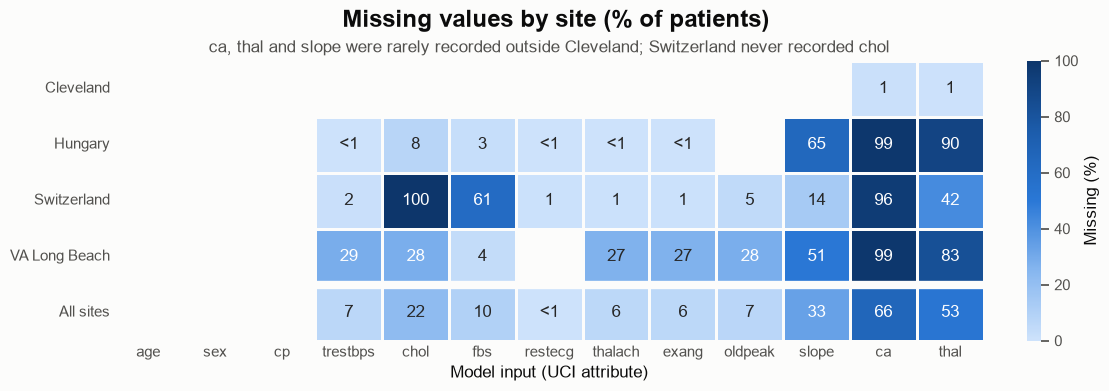

In [9]:
eda.plot_missingness_by_site(df)

In [10]:
missing = df[INPUT_FEATURES].isna()
complete = (~missing.any(axis=1)).groupby(df["site"]).mean().rename("complete rows")
never_missing = [col for col in INPUT_FEATURES if not missing[col].any()]
print(f"never missing at any site: {never_missing}")
complete.rename(index=eda.SITE_NAMES).to_frame().T

never missing at any site: ['age', 'sex', 'cp']


site,Cleveland,Hungary,Switzerland,VA Long Beach
complete rows,0.98,0.003,0.0,0.005


- Missingness is structural, not random: `ca` is missing for 99% of Hungarian and VA patients
  and 96% of Swiss patients, `thal` for 90%, 83% and 42%, and Switzerland never recorded `chol`.
  Cleveland is essentially complete.
- As a result, 98% of Cleveland rows are complete but fewer than 1% of the rows from any other
  site are. Dropping incomplete rows would silently reduce the study back to Cleveland.
- `age`, `sex` and `cp` are never missing, which is why they are the only fields the API
  requires; every other field may be omitted and is imputed by the pipeline.

Because each hospital skipped different tests, *which* fields are missing says a lot about where
a patient came from, and where a patient came from says a lot about the label. The cell below
measures both links.

In [11]:
y = df[config.TARGET]
site_rate = y.groupby(df["site"]).transform("mean")
pattern = missing.astype(int).astype(str).agg("".join, axis=1)
site_from_pattern = pd.crosstab(pattern, df["site"]).max(axis=1).sum() / len(df)
print(f"ROC-AUC of the site's prevalence alone:       {roc_auc_score(y, site_rate):.3f}")
print(f"ROC-AUC of 'chol is missing' alone:           {roc_auc_score(y, missing['chol']):.3f}")
print(f"distinct missingness patterns:                {pattern.nunique()}")
print(f"site identified from the pattern (in-sample): {site_from_pattern:.1%}")

ROC-AUC of the site's prevalence alone:       0.719
ROC-AUC of 'chol is missing' alone:           0.614
distinct missingness patterns:                35
site identified from the pattern (in-sample): 86.1%


- Knowing only the hospital ranks patients with ROC-AUC 0.72, and the single flag "cholesterol
  missing" already reaches 0.61, with no clinical information at all.
- The 35 distinct missingness patterns identify the site for 86% of patients. So even with
  `site` removed from the inputs, the missing-value indicators can partly reconstruct it.
- This cuts both ways. The indicators carry real signal (a test not ordered is itself clinical
  information) and the pipeline keeps them, but part of a pooled CV score can come from
  recognising the hospital rather than the patient. That is exactly what the leave-one-site-out
  evaluation in training measures (section 8).

## 4. Numeric inputs by diagnosis

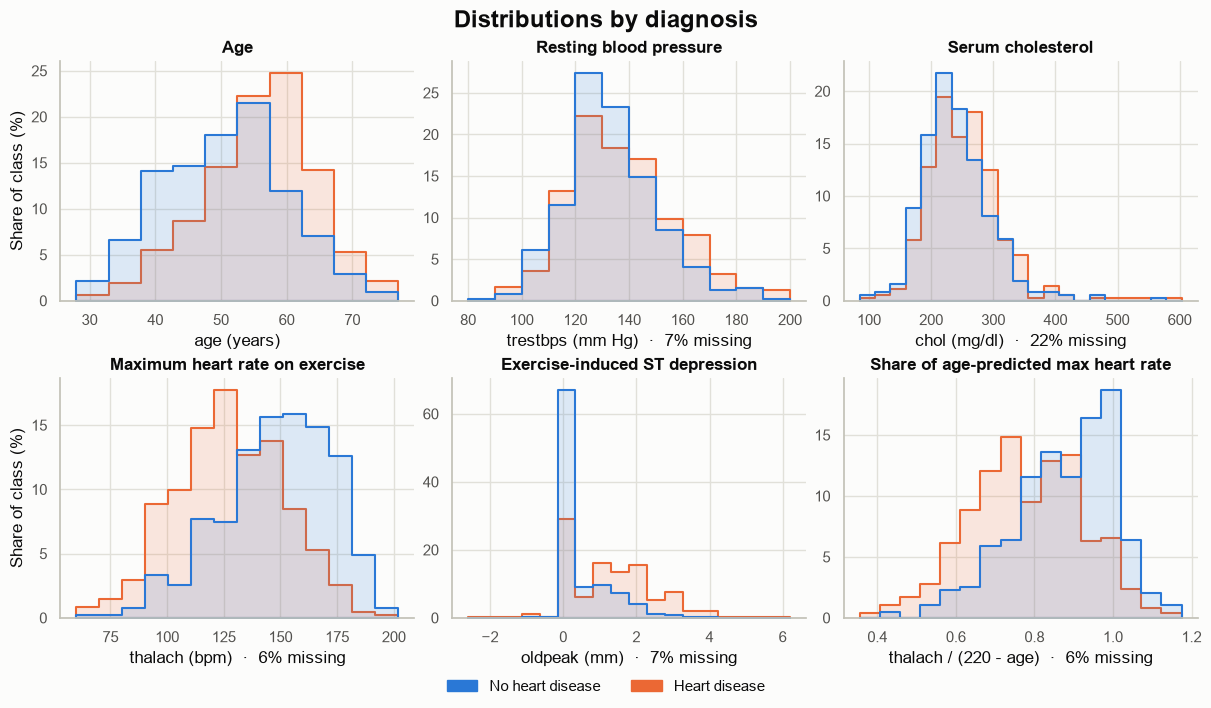

In [12]:
eda.plot_numeric_distributions(df)

In [13]:
features = add_clinical_features(df).join(y)
medians = features.groupby(config.TARGET)[NUMERIC].median().rename(index=eda.CLASS_NAMES)
pd.concat([medians, features[NUMERIC].isna().mean().rename("share missing").to_frame().T])

,age,trestbps,chol,thalach,oldpeak,hr_achieved_frac
No heart disease,51.0,130.000,233.000,151.00,0.000,0.898
Heart disease,57.0,130.000,248.000,128.00,1.100,0.772
share missing,0.0,0.065,0.219,0.06,0.068,0.060


- The exercise-test variables separate the classes best: median `thalach` is 151 bpm without
  disease vs 128 bpm with disease, and median `oldpeak` 0.0 vs 1.1 mm. The derived
  `hr_achieved_frac` shows the same shift (0.90 vs 0.77).
- Patients with disease are older (median 57 vs 51 years); resting blood pressure has the same
  median (130 mm Hg) in both classes and adds little on its own.
- `chol` overlaps heavily between classes and is missing for 22% of patients, mostly by site.
  Scales differ by two orders of magnitude (`oldpeak` in mm, `chol` in mg/dl), so the pipeline
  standardises numerics for the regularised logistic regression.

## 5. Correlations

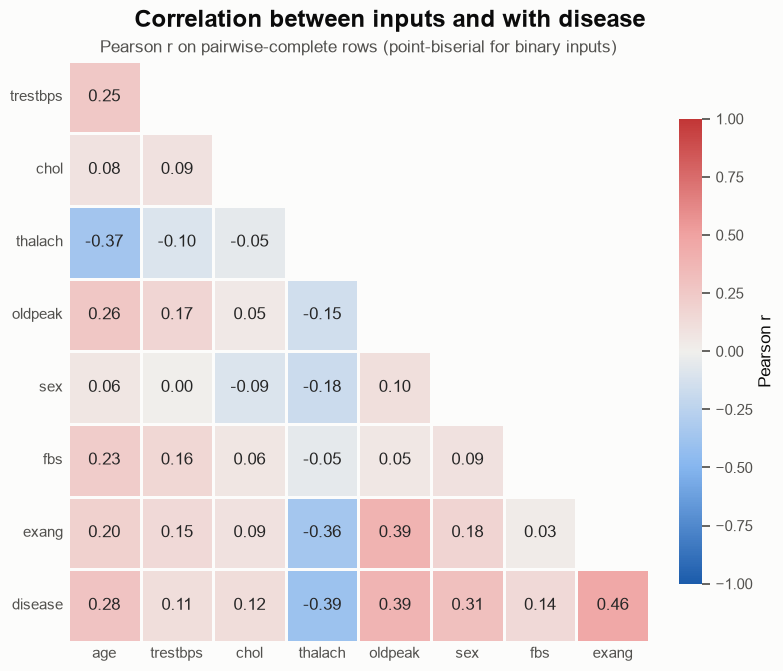

In [14]:
eda.plot_correlation_heatmap(df)

In [15]:
corr_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "sex", "fbs", "exang"]
corr = df[[*corr_cols, config.TARGET]].corr()
with_target = corr[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False)
pairs = corr.loc[corr_cols, corr_cols].where(lambda c: c.abs() < 1).abs().stack()
print(f"strongest input pair: {pairs.idxmax()}, |r| = {pairs.max():.2f}")
with_target.rename("r with disease").to_frame().T

strongest input pair: ('oldpeak', 'exang'), |r| = 0.39


,exang,thalach,oldpeak,sex,age,fbs,chol,trestbps
r with disease,0.462,-0.393,0.386,0.305,0.282,0.143,0.119,0.115


- The strongest single correlates of disease are `exang` (r = 0.46), `oldpeak` (0.39),
  `thalach` (-0.39) and `sex` (0.31): three of the four come from the exercise test.
- Among the inputs, the strongest pair is `exang` with `oldpeak` at |r| = 0.39, followed by
  `age` with `thalach` (-0.37). No pair is close to collinear, so no input needs to be dropped;
  the elastic-net penalty handles the moderate redundancy that exists.
- `chol` correlates only 0.12 with disease on the rows where it was measured, consistent with
  its weak separation in section 4.

## 6. Categorical inputs: disease rate per category

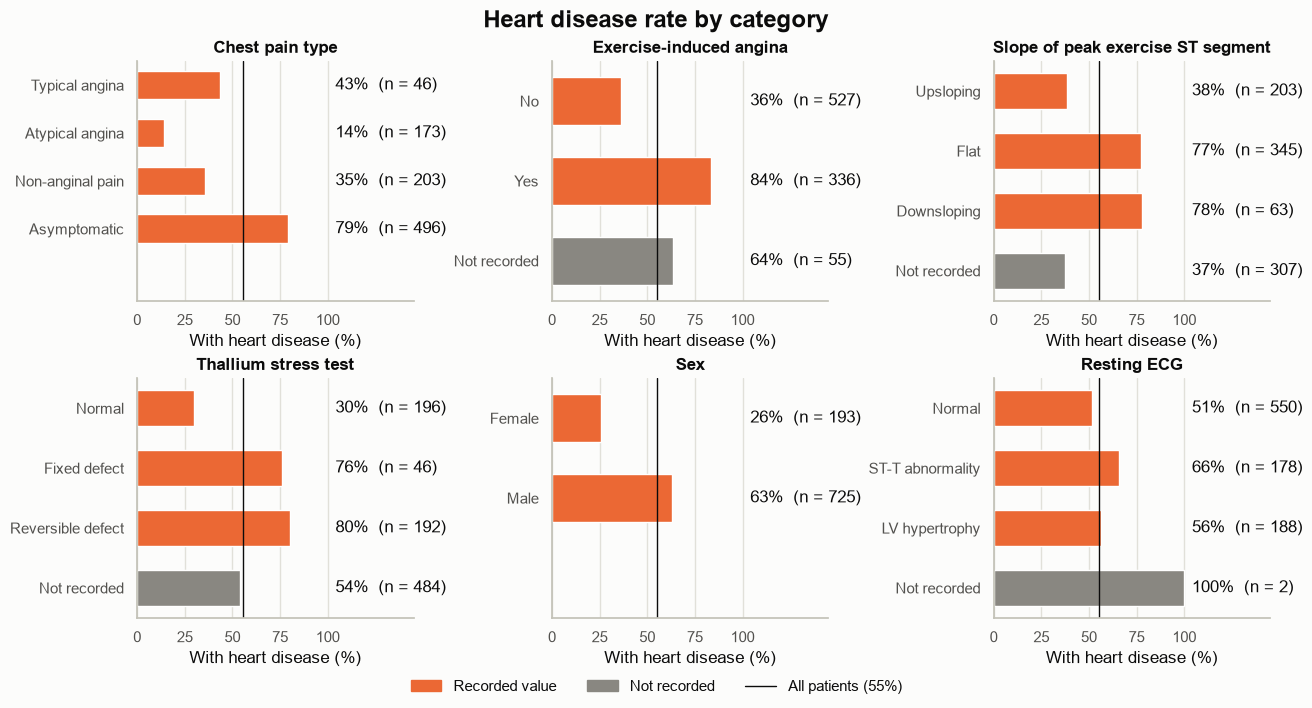

In [16]:
eda.plot_categorical_rates(df)

In [17]:
rows = []
for col in ["cp", "exang", "slope", "thal", "ca"]:
    level = df[col].map(lambda v: "missing" if pd.isna(v) else f"{v:g}")
    stats = y.groupby(level).agg(["mean", "size"])
    rows.append(stats.set_axis(pd.MultiIndex.from_product([[col], stats.index])))
pd.concat(rows).rename(columns={"mean": "disease_rate", "size": "patients"})

disease_rate  patients
cp    1               0.435        46
      2               0.139       173
      3               0.355       203
      4               0.790       496
exang 0               0.364       527
      1               0.836       336
      missing         0.636        55
slope 1               0.384       203
      2               0.771       345
      3               0.778        63
      missing         0.375       307
thal  3               0.296       196
      6               0.761        46
      7               0.802       192
      missing         0.539       484
ca    0               0.265       181
      1               0.687        67
      2               0.805        41
      3               0.850        20
      missing         0.598       609

- Asymptomatic chest pain (`cp = 4`, 496 patients) has a 79% disease rate, far above typical or
  atypical angina (43% and 14%). The ordinal codes are not monotonic in risk, so `cp` is one-hot
  encoded rather than treated as a number.
- Exercise-induced angina raises the rate from 36% to 84%; a flat or downsloping ST segment
  (`slope` 2 or 3) about doubles it relative to upsloping (77-78% vs 38%).
- The "not recorded" bars are informative in their own right: patients with unrecorded `thal`
  have a 54% disease rate and unrecorded `ca` 60%, neither matching any recorded level. This is
  why the one-hot encoder keeps NaN as its own category instead of imputing the mode.

## 7. Maximum heart rate vs age

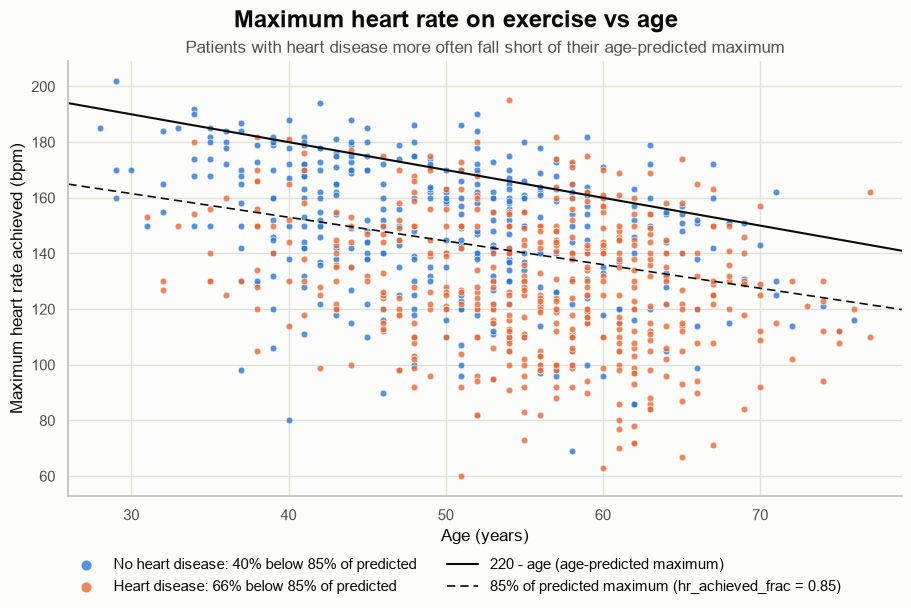

In [18]:
eda.plot_max_hr_vs_age(df)

In [19]:
measured = features.dropna(subset=["hr_achieved_frac"])
below = measured["hr_achieved_frac"].lt(0.85).groupby(measured[config.TARGET]).mean()
print(
    f"{len(measured)} patients with thalach; below 85% of age-predicted maximum: "
    f"{below[0]:.0%} without disease, "
    f"{below[1]:.0%} with disease"
)
features[["thalach", "hr_achieved_frac", config.TARGET]].corr().round(2)

863 patients with thalach; below 85% of age-predicted maximum: 40% without disease, 66% with disease


,thalach,hr_achieved_frac,target
thalach,1.00,0.95,-0.39
hr_achieved_frac,0.95,1.00,-0.33
target,-0.39,-0.33,1.00


- Maximum heart rate falls with age (r = -0.37 between `age` and `thalach`), so a raw `thalach`
  of 130 bpm means something different at 40 than at 70. The clinical convention normalises it by
  the age-predicted maximum `220 - age`.
- Among the 863 patients with a recorded `thalach`, 66% of those with disease fail to reach 85%
  of their predicted maximum (chronotropic incompetence), against 40% of those without.
- `hr_achieved_frac` is correlated 0.95 with `thalach`, so it is a re-expression rather than new
  information, and it correlates slightly less with the target (-0.33 vs -0.39). It is kept
  because it encodes an age interaction a linear model cannot form by itself and a clinician can
  read it directly; the regularised model decides how much weight it gets.

## 8. Implications for modelling

Each finding above maps to a concrete decision in `cardiorisk.features.build_pipeline` or
`cardiorisk.train`:

| Finding | Pipeline decision |
| --- | --- |
| Missingness is structural and informative (sections 3, 6): < 1% of non-Cleveland rows are complete, and unrecorded `ca`/`thal` have their own disease rates | Never drop rows. Median (numeric) and most-frequent (binary) imputation with `add_indicator=True`; the `OneHotEncoder` keeps NaN as its own category. The API accepts records with only `age`, `sex`, `cp`. |
| Prevalence ranges 36-93% by site and site alone gives ROC-AUC 0.72 (sections 2, 3) | `site` is never a model input: a deployed model sees a patient, not a hospital label, and a site feature would learn referral patterns rather than physiology. |
| The missingness pattern recovers the site for 86% of patients (section 3) | Report leave-one-site-out ROC-AUC (train on three sites, score the fourth) next to the pooled CV score, to expose how much performance depends on the hospital mix. |
| Small sites with extreme prevalence (Switzerland: 8 negatives) | The 80/20 hold-out and the 5 CV folds are stratified on site x class, so every fold sees every hospital at its own prevalence. |
| Heart rate depends on age (section 7) | `add_clinical_features` adds `hr_achieved_frac = thalach / (220 - age)` inside the pipeline, so training and serving compute it identically. |
| Non-monotonic codes in `cp`, `restecg`, `slope`, `ca`, `thal` (section 6) | One-hot encode categoricals; standardise numerics whose scales differ by 100x (section 4). |
| Prevalence varies with the site mix, so the best threshold does too | Select the champion on mean CV ROC-AUC, which is threshold-free and insensitive to prevalence; accuracy, precision, recall and F1 at 0.5 are reported alongside. |

**Outcome.** With these choices the champion (elastic-net logistic regression) reaches CV
ROC-AUC 0.907 +/- 0.029 and hold-out ROC-AUC 0.906. Leave-one-site-out ROC-AUC is 0.876
(Cleveland) and 0.902 (Hungary) but drops to 0.749 (Switzerland) and 0.730 (VA): the model
transfers well between the two balanced sites and less well to the high-prevalence sites with
the most missing data, the limitation this notebook predicted. See `reports/metrics.md`.

**Next step.** `make train` fits the four candidate families with grid search, logs every run to
MLflow (experiment `cardiorisk-heart-disease`; browse with `make mlflow-ui`) and writes the
champion to `models/cardiorisk_model.joblib`. `make eda` regenerates the figures above as
`reports/figures/eda_*.png`.